<a href="https://colab.research.google.com/github/mlser1706/Antibody-Engineering/blob/main/week06/week06_predicting_complexes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 — Predicting the Complex

**Computational Antibody Engineering**

You can predict an antibody (week 4). You can predict an antigen (week 5). Today you predict them
**bound to each other** — and find out why that is a different problem, not just a bigger one.

> **Can a co-folding model put an antibody on the right part of its antigen, in the right orientation?**
> **And does its confidence score tell you whether it did?**

### How today works

Co-folding needs serious compute, so this session splits in two:

- **Part A (now, in the notebook):** learn the evaluation metric, calibrate your intuition for what its
  values mean, and measure a hard ceiling on what any co-folding model could achieve here.
- **Part B (you, at [alphafoldserver.com](https://alphafoldserver.com/)):** submit the real prediction
  yourself, several times, then bring the results back here to score and pool with the class.

Start Part B's first submission **before** you work through Part A — jobs take a few minutes and you
want them running while you read.

### Today's target
**PDB `1VFB`** — the D1.3 antibody Fv bound to hen egg lysozyme. Small (352 residues total), a classic
benchmark, and well within the AlphaFold Server's per-job size limit.

## 0. Setup and first submission

**Do this first, then come back.**

### Submitting to the AlphaFold Server

1. Go to [alphafoldserver.com](https://alphafoldserver.com/) and sign in with a Google account.
2. Add **three protein chains** and paste the sequences printed by the cell below.
3. Run the job. Then **run the same job again**, several times — each run uses a different random seed
   and gives different answers. Aim for **3–5 runs**.
4. Download each result (a `.zip` containing `.cif` model files and `.json` confidence files) and
   upload them to this Colab session.

**Usage limits and terms — read these, they are part of the lesson.** The server is free for
non-commercial use, with a daily cap on jobs per account (on the order of a few tens). That cap is why
**each of you runs your own seeds on your own account** and we pool results, rather than one person
batching for the class. The terms also restrict what outputs may be used for — notably they may not be
used to train other structure-prediction models. Tool licences constrain real projects as much as tool
accuracy does; this is a live example.

In [1]:
!pip freeze | grep -iE '^(numpy|pandas|scipy|matplotlib)==' > /tmp/pins.txt

%pip install -q -c /tmp/pins.txt biopython ImmuneBuilder anarci openmm pdbfixer networkx parallelbar cython
%pip install -q --no-deps --no-build-isolation DockQ

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
print("numpy", np.__version__, "| pandas", pd.__version__)

from Bio.PDB import PDBParser, MMCIFParser, PDBIO, Superimposer
from Bio.PDB.Structure import Structure
from Bio.PDB.Model import Model
from Bio.PDB.Chain import Chain
from Bio.PDB.Polypeptide import three_to_index, index_to_one
from DockQ.DockQ import load_PDB, run_on_all_native_interfaces
import urllib.request, os, json, glob

pdb_parser = PDBParser(QUIET=True)
cif_parser = MMCIFParser(QUIET=True)
STANDARD = {"ALA","ARG","ASN","ASP","CYS","GLN","GLU","GLY","HIS","ILE",
            "LEU","LYS","MET","PHE","PRO","SER","THR","TRP","TYR","VAL"}

if not os.path.exists("1VFB.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1VFB.pdb", "1VFB.pdb")
s_struct = pdb_parser.get_structure("1VFB", "1VFB.pdb")
crystal = s_struct[0]


def sequence_of(chain):
    residues = [r for r in chain if r.id[0] == " "]
    seq = "".join(index_to_one(three_to_index(r.get_resname()))
                  if r.get_resname() in STANDARD else "X" for r in residues)
    return seq, residues


VL, vl_res = sequence_of(crystal["A"])
VH, vh_res = sequence_of(crystal["B"])
AG, ag_res = sequence_of(crystal["C"])

print("=" * 70)
print("PASTE THESE THREE SEQUENCES INTO alphafoldserver.com AS 3 PROTEIN CHAINS")
print("=" * 70)
for name, seq in [("Light chain (VL)", VL), ("Heavy chain (VH)", VH), ("Lysozyme (antigen)", AG)]:
    print(f"\n>{name}  [{len(seq)} residues]")
    print(seq)
print(f"\n{'=' * 70}\nTotal: {len(VL) + len(VH) + len(AG)} residues")

numpy 2.4.6 | pandas 2.2.3
PASTE THESE THREE SEQUENCES INTO alphafoldserver.com AS 3 PROTEIN CHAINS

>Light chain (VL)  [107 residues]
DIVLTQSPASLSASVGETVTITCRASGNIHNYLAWYQQKQGKSPQLLVYYTTTLADGVPSRFSGSGSGTQYSLKINSLQPEDFGSYYCQHFWSTPRTFGGGTKLEIK

>Heavy chain (VH)  [116 residues]
QVQLQESGPGLVAPSQSLSITCTVSGFSLTGYGVNWVRQPPGKGLEWLGMIWGDGNTDYNSALKSRLSISKDNSKSQVFLKMNSLHTDDTARYYCARERDYRLDYWGQGTTLTVSS

>Lysozyme (antigen)  [129 residues]
KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRNTDGSTDYGILQINSRWWCNDGRTPGSRNLCNIPCSALLSSDITASVNCAKKIVSDGNGMNAWVAWRNRCKGTDVQAWIRGCRL

Total: 352 residues


## 1. Why this is the hardest prediction in the course

Co-folding models (AlphaFold 3, Boltz, Chai) predict all chains of a complex together, so the
components can adapt to each other. They work impressively well on many protein–protein complexes.
Antibody–antigen is the case where they struggle most, and the reason is worth understanding properly.

**Most protein–protein prediction quietly relies on co-evolution.** If two proteins have interacted
across millions of years of evolution, a mutation on one side tends to be compensated by a mutation on
the other. That statistical echo is visible in a multiple sequence alignment, and it is a large part of
how these models infer which surfaces touch.

**Antibody–antigen interfaces have no such history.** The antibody was generated in weeks, in one
animal, by V(D)J recombination and somatic hypermutation. It has never co-evolved with its antigen. The
CDR loops — CDR-H3 above all (week 2) — are the *least* conserved part of the molecule. There is no
co-evolutionary signal to find, because there is no co-evolution.

So the model must work from geometry and from patterns memorised across known antibody complexes. That
is a much weaker position, and it is why published success rates for antibody–antigen co-folding are
far below those for general protein complexes.

**A related warning about a different metric.** Boltz-2 added an affinity-prediction module, and you
will see it cited. Its affinity capability is aimed at small-molecule binders and does not transfer to
antibody–antigen affinity. Do not read any co-folding confidence score as a binding constant — a point
we return to at the end of today.

## 2. DockQ: how wrong is a predicted complex?

RMSD is a poor measure for a complex. Superpose on the antibody and the antigen error looks enormous;
superpose on everything and you hide where the error actually is.

**DockQ** is the standard alternative. It combines three measurements into one number from 0 to 1:

| Component | What it measures |
|---|---|
| **fnat** | fraction of the true interface contacts that the model reproduces |
| **iRMSD** | backbone RMSD of the interface residues only |
| **LRMSD** | RMSD of the smaller partner after superposing on the larger one |

DockQ maps onto the CAPRI quality classes used throughout the docking literature:

| DockQ | CAPRI class |
|---|---|
| ≥ 0.80 | **high** |
| 0.49 – 0.80 | **medium** |
| 0.23 – 0.49 | **acceptable** |
| < 0.23 | **incorrect** |

DockQ compares *interfaces*, so we first reshape both structures into two chains: **A** = the whole Fv
(VL and VH merged, because we care about the Fv–antigen interface as a unit) and **B** = the antigen.

In [3]:
def write_two_chain(groups, out_path):
    """Write a 2-chain PDB. `groups` is [(chain_id, [residues]), ...], renumbered sequentially."""
    struct = Structure("s")
    model = Model(0)
    struct.add(model)
    for chain_id, residues in groups:
        chain = Chain(chain_id)
        for n, r in enumerate(residues, start=1):
            rr = r.copy()
            rr.id = (" ", n, " ")
            chain.add(rr)
        model.add(chain)
    io = PDBIO()
    io.set_structure(struct)
    io.save(out_path)
    return out_path


def dockq_score(model_pdb, native_pdb):
    """DockQ for a 2-chain model against a 2-chain native."""
    native = load_PDB(native_pdb, chains=["A", "B"])
    model = load_PDB(model_pdb, chains=["A", "B"])
    result, _ = run_on_all_native_interfaces(model, native, chain_map={"A": "A", "B": "B"})
    return result[list(result)[0]]


def capri_class(dockq):
    if dockq >= 0.80: return "high"
    if dockq >= 0.49: return "medium"
    if dockq >= 0.23: return "acceptable"
    return "INCORRECT"


ordered = lambda c: [r for r in crystal[c] if r.id[0] == " "]
write_two_chain([("A", ordered("A") + ordered("B")), ("B", ordered("C"))], "native.pdb")

check = dockq_score("native.pdb", "native.pdb")
print(f"native scored against itself: DockQ = {check['DockQ']:.3f}")
print(f"  interface contacts in the crystal: {check['nat_total']}")
print(f"  Fv residues {check['len1']}, antigen residues {check['len2']}")

native scored against itself: DockQ = 1.000
  interface contacts in the crystal: 47
  Fv residues 223, antigen residues 129


### Calibrating your intuition

A number between 0 and 1 means nothing until you know what it looks like. So let's make deliberately
wrong answers of known wrongness: take the true complex and **rotate the antigen in place** by
increasing angles. The binding site stays in roughly the same region — only the orientation degrades.

Guess, before you run it: how far can you rotate the antigen before the answer stops counting as
correct?

In [4]:
def rotate_antigen(degrees, out_path):
    """Rotate the antigen about its own centre of mass - the pose degrades, position roughly holds."""
    m = pdb_parser.get_structure("n", "native.pdb")[0]
    atoms = [a for r in m["B"] for a in r]
    centre = np.mean([a.coord for a in atoms], axis=0)
    t = np.radians(degrees)
    R = np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1]])
    for a in atoms:
        a.coord = R @ (a.coord - centre) + centre
    io = PDBIO(); io.set_structure(m); io.save(out_path)
    return out_path


rows = []
for deg in [0, 2, 5, 10, 15, 20, 30, 45, 90]:
    d = dockq_score(rotate_antigen(deg, f"decoy_{deg}.pdb"), "native.pdb")
    rows.append({"rotation_deg": deg, "DockQ": round(d["DockQ"], 3),
                 "fnat": round(d["fnat"], 2), "iRMSD": round(d["iRMSD"], 2),
                 "LRMSD": round(d["LRMSD"], 2), "CAPRI": capri_class(d["DockQ"])})

ladder = pd.DataFrame(rows)
ladder

,rotation_deg,DockQ,fnat,iRMSD,LRMSD,CAPRI
0,0,1.000,1.00,0.00,0.00,high
1,2,0.970,0.94,0.23,0.42,high
2,5,0.896,0.83,0.57,1.05,high
3,10,0.774,0.74,1.14,2.11,medium
4,15,0.637,0.60,1.71,3.16,medium
5,20,0.532,0.49,2.27,4.20,medium
6,30,0.370,0.30,3.39,6.26,acceptable
7,45,0.215,0.11,5.03,9.25,INCORRECT
8,90,0.074,0.00,9.36,17.10,INCORRECT


### YOUR TURN — Question 1

From the ladder:

1. At what rotation does the answer drop out of **high** quality? Out of **medium**?
2. At what rotation does DockQ call the prediction **incorrect**? Is that stricter or more forgiving
   than you guessed?
3. A 20° rotation still scores in the **medium** band. Picture what a 20° error means physically — the
   antigen twisted on the paratope. Would a design decision based on specific residue–residue contacts
   survive that error? (Look at the `fnat` column: what fraction of true contacts is left?)
4. DockQ 0.23 is the floor for "acceptable". Given what you just saw, would you be comfortable calling
   a DockQ 0.3 model a usable structure? For what purpose?

*Double-click and write your answers here.*

1. Even a small rotation of just 2 to 3 degrees drops the score out of the high quality band. A rotation of 15 to 20 degrees drops it from medium to acceptable.
2. DockQ classifies a prediction as incorrect when the score drops below 0.23 (around 30 to 45 degrees of rotation). This is stricter than we might guess by just looking at the protein structure visually.
3. No, a 20-degree rotation is still in the medium band, but looking at the fnat column, most of the true residue-to-residue contacts are lost. Therefore, a design decision based on specific atomic contacts would not survive that error.
4. Yes, a DockQ 0.3 model can be useful to see the general region or approximate binding site of the antigen, but it is not reliable enough for precise residue-level mutation design.

**The point of the ladder:** DockQ is demanding, and correctly so. Even a modest rotation destroys
most of the specific contacts, while the complex still *looks* broadly right if you squint at a cartoon.
"The antibody is on the right part of the antigen" and "the model reproduces the interface" are
different claims, and only the second supports residue-level work.

## 3. A ceiling nobody can beat

Before judging any co-folding model, ask what the **best possible** answer would be with the components
we have.

Here is the experiment. Take:

- the **predicted** Fv from ABodyBuilder2 (week 4's tool), and
- the **predicted** antigen from the AlphaFold Database (week 5's source),

then place each one **exactly** where the crystal says it should be. That is a perfect docking result —
zero pose error — built from imperfect parts. Whatever DockQ that scores is an **upper bound** on what
any co-folding model could achieve with components of this quality.

*(This cell downloads the ABodyBuilder2 weights on first use — a few minutes. Start it and keep reading.)*

In [5]:
!apt-get -qq install -y hmmer > /dev/null
!which hmmscan && hmmscan -h | head -2

/usr/bin/hmmscan
# hmmscan :: search sequence(s) against a profile database
# HMMER 3.4 (Aug 2023); http://hmmer.org/


In [6]:
from ImmuneBuilder import ABodyBuilder2
from anarci import number

predictor = ABodyBuilder2()
predictor.predict({"H": VH, "L": VL}).save("Fv_pred.pdb")

# AlphaFold model of hen egg lysozyme
UNIPROT = "P00698"
meta = json.load(urllib.request.urlopen(
    f"https://alphafold.ebi.ac.uk/api/prediction/{UNIPROT}"))[0]
if not os.path.exists("AF_antigen.pdb"):
    urllib.request.urlretrieve(meta["pdbUrl"], "AF_antigen.pdb")
af_antigen = pdb_parser.get_structure("af", "AF_antigen.pdb")[0]["A"]

# Antigen numbering offset - derive it, never assume it (week 5's lesson, different answer)
af_seq, af_res = sequence_of(af_antigen)
start = af_seq.find(AG[:25])
AG_OFFSET = af_res[start].id[1] - ag_res[0].id[1]
print(f"antigen offset = {AG_OFFSET}  (signal peptide: {af_seq[:AG_OFFSET]})")

# Superpose the predicted Fv onto the crystal Fv, by IMGT position
def imgt_map(residues, seq):
    numbering, _ = number(seq, scheme="imgt")
    occupied = [(p, a) for (p, ic), a in numbering if a != "-"]
    return {p: residues[i] for i, (p, a) in enumerate(occupied)}

pred_fv = pdb_parser.get_structure("p", "Fv_pred.pdb")[0]
pairs_c, pairs_p = [], []
for cryst_map, pred_chain in [(imgt_map(vh_res, VH), "H"), (imgt_map(vl_res, VL), "L")]:
    pmap = {r.id[1]: r for r in pred_fv[pred_chain] if r.id[0] == " "}
    for p in sorted(set(cryst_map) & set(pmap)):
        if "CA" in cryst_map[p] and "CA" in pmap[p] and \
           cryst_map[p].get_resname() == pmap[p].get_resname():
            pairs_c.append(cryst_map[p]["CA"]); pairs_p.append(pmap[p]["CA"])

sup = Superimposer(); sup.set_atoms(pairs_c, pairs_p)
print(f"predicted Fv vs crystal Fv:       {sup.rms:.2f} A")
sup.apply([a for c in pred_fv for r in c for a in r])

# Superpose the predicted antigen onto the crystal antigen
af_by_pos = {r.id[1] - AG_OFFSET: r for r in af_antigen if r.id[0] == " "}
cr_by_pos = {r.id[1]: r for r in ag_res}
shared = [p for p in sorted(set(af_by_pos) & set(cr_by_pos))
          if af_by_pos[p].get_resname() == cr_by_pos[p].get_resname()]
sup2 = Superimposer()
sup2.set_atoms([cr_by_pos[p]["CA"] for p in shared], [af_by_pos[p]["CA"] for p in shared])
print(f"predicted antigen vs crystal:     {sup2.rms:.2f} A")
sup2.apply([a for r in af_antigen for a in r])

write_two_chain([("A", [r for r in pred_fv["L"] if r.id[0] == " "] +
                       [r for r in pred_fv["H"] if r.id[0] == " "]),
                 ("B", [af_by_pos[p] for p in shared])], "ceiling_model.pdb")
write_two_chain([("A", ordered("A") + ordered("B")),
                 ("B", [cr_by_pos[p] for p in shared])], "native_matched.pdb")

ceiling = dockq_score("ceiling_model.pdb", "native_matched.pdb")
print(f"\nPERFECT POSE, predicted components -> DockQ = {ceiling['DockQ']:.3f} "
      f"({capri_class(ceiling['DockQ'])})")
print(f"   fnat {ceiling['fnat']:.2f}  iRMSD {ceiling['iRMSD']:.2f}  LRMSD {ceiling['LRMSD']:.2f}")

antigen offset = 18  (signal peptide: MRSLLILVLCFLPLAALG)
predicted Fv vs crystal Fv:       0.41 A
predicted antigen vs crystal:     1.11 A

PERFECT POSE, predicted components -> DockQ = 0.801 (high)
   fnat 0.77  iRMSD 1.10  LRMSD 1.09


### Read that number carefully

Both components are **excellent** — an Fv within about half an ångström and an antigen within about one
ångström of the crystal. We then placed them with **zero** pose error, which no real method achieves.

And the result sits right at the boundary of "high quality", having already lost roughly a quarter of
the true interface contacts.

**That is the ceiling.** A co-folding model does not get the pose for free; it has to find it. So with
components of this quality it cannot do better than this, and will normally do considerably worse.

Two consequences worth carrying:

- **Small component errors are amplified at an interface.** Sub-ångström errors on each side, in a
  perfect pose, still cost you a quarter of the contacts. An interface is where the two error budgets
  meet, so it is the least forgiving place to measure.
- **When you judge your AlphaFold Server results in a moment, judge them against this ceiling**, not
  against 1.0. Comparing to a perfect score you could never reach tells you nothing about the model.

## 4. Score your own predictions

Now bring in your AlphaFold Server downloads.

Upload the `.zip` files (or the extracted folders) to this Colab session, then run the cell below. It
looks for model `.cif` files and their matching confidence `.json` files.

**Server output formats change.** The cell prints what it finds rather than assuming a layout. If it
does not find your files, look at the printed directory listing and adjust the pattern — and if the
JSON keys differ from what it expects, it will show you the keys it did find so you can pick the right
one.

In [9]:
import zipfile

for z in glob.glob("*.zip"):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(z.replace(".zip", ""))
    print(f"extracted {z}")

cif_files = sorted(glob.glob("**/*.cif", recursive=True))
json_files = sorted(glob.glob("**/*.json", recursive=True))

print(f"\nfound {len(cif_files)} .cif files and {len(json_files)} .json files")
for f in cif_files[:10]:
    print("   ", f)

if json_files:
    with open(json_files[0]) as fh:
        sample = json.load(fh)
    keys = list(sample.keys()) if isinstance(sample, dict) else "top level is a list"
    print(f"\nkeys in {json_files[0]}:\n   {keys}")
else:
    print("\nNo JSON found yet - submit jobs at alphafoldserver.com and upload the results.")

extracted fold_2026_11_12_19_08.zip

found 17 .cif files and 15 .json files
    fold_2026_11_12_19_08/fold_2026_11_12_19_08_model_0.cif
    fold_2026_11_12_19_08/fold_2026_11_12_19_08_model_1.cif
    fold_2026_11_12_19_08/fold_2026_11_12_19_08_model_2.cif
    fold_2026_11_12_19_08/fold_2026_11_12_19_08_model_3.cif
    fold_2026_11_12_19_08/fold_2026_11_12_19_08_model_4.cif
    fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_a.cif
    fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_b.cif
    fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_c.cif
    fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_1_chains_a.cif
    fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_1_chains_b.cif

keys in fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_0.json:
   ['atom_chain_ids', 'atom_plddts', 'contact_probs', 'pae', 'token_chain_ids', 'token_res_ids']


In [10]:
def find_confidence(obj, wanted=("iptm", "ptm")):
    """Pull confidence values out of a server JSON, tolerating naming differences."""
    out = {}
    def walk(o):
        if isinstance(o, dict):
            for k, v in o.items():
                kl = k.lower().replace("_", "")
                for w in wanted:
                    if kl == w and isinstance(v, (int, float)):
                        out.setdefault(w, float(v))
                walk(v)
        elif isinstance(o, list):
            for v in o[:50]:
                walk(v)
    walk(obj)
    return out


def score_cif(cif_path, ab_chains, ag_chains, native="native.pdb"):
    """DockQ for one AlphaFold Server model."""
    m = cif_parser.get_structure("m", cif_path)[0]
    keep = lambda c: [r for r in m[c] if r.id[0] == " "]
    ab = [r for c in ab_chains for r in keep(c)]
    ag = [r for c in ag_chains for r in keep(c)]
    write_two_chain([("A", ab), ("B", ag)], "_tmp_model.pdb")
    return dockq_score("_tmp_model.pdb", native)


# Inspect chain naming in your first model before scoring the rest.
if cif_files:
    m0 = cif_parser.get_structure("m", cif_files[0])[0]
    print("chains in your first model:")
    for c in m0:
        n = len([r for r in c if r.id[0] == " "])
        print(f"   chain {c.id}: {n} residues")
    print(f"\nFor reference: VL={len(VL)}, VH={len(VH)}, antigen={len(AG)} residues.")
    print("Set AB_CHAINS and AG_CHAINS below to match.")

chains in your first model:
   chain A: 107 residues
   chain B: 116 residues
   chain C: 129 residues

For reference: VL=107, VH=116, antigen=129 residues.
Set AB_CHAINS and AG_CHAINS below to match.


In [12]:
# YOUR TURN: set these from the chain listing above.
AB_CHAINS = ["A", "B"]      # the two antibody chains
AG_CHAINS = ["C"]           # the antigen

records = []
for cif in cif_files:
    try:
        d = score_cif(cif, AB_CHAINS, AG_CHAINS)
    except Exception as e:
        print(f"could not score {cif}: {type(e).__name__}")
        continue

    stem = os.path.basename(cif).replace(".cif", "")
    conf = {}
    for j in json_files:
        if "summary" in j.lower() and stem.split("model")[0] in os.path.basename(j):
            with open(j) as fh:
                conf = find_confidence(json.load(fh))
            break

    records.append({"model": stem,
                    "ipTM": conf.get("iptm"), "pTM": conf.get("ptm"),
                    "DockQ": round(d["DockQ"], 3), "fnat": round(d["fnat"], 2),
                    "iRMSD": round(d["iRMSD"], 2), "LRMSD": round(d["LRMSD"], 2),
                    "CAPRI": capri_class(d["DockQ"])})

my_results = pd.DataFrame(records)
if len(my_results):
    my_results = my_results.sort_values("DockQ", ascending=False)
    print(my_results.to_string(index=False))
    my_results.to_csv("my_results.csv", index=False)
    print("\nsaved my_results.csv - upload this to the class spreadsheet")
else:
    print("No models scored yet. Complete Part B, then re-run.")

could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_a.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_b.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_0_chains_c.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_1_chains_a.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_1_chains_b.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_1_chains_c.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_2_chains_a.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_2_chains_b.cif: KeyError
could not score fold_2026_11_12_19_08/templates/fold_2026_11_12_19_08_template_hit_2_chains_c.cif: KeyError
could not score fold_2026_11

**If ipTM came back empty**, open your summary JSON, find the confidence value by eye, and add it by
hand — `my_results.loc[0, "ipTM"] = 0.83` and so on. Do not skip it; the next section needs it.

### The confidence metrics, briefly

| Metric | Range | What it refers to |
|---|---|---|
| **pLDDT** | 0–100 | per-residue local confidence (week 5) |
| **pTM** | 0–1 | confidence in the fold of the whole complex |
| **ipTM** | 0–1 | confidence in the **interface** — the relative placement of chains |
| **PAE** | Å | expected error in the position of residue *x* given residue *y*; the off-diagonal blocks describe inter-chain placement |

For a complex, **ipTM is the one that matters**, because it is the only one that speaks to whether the
chains are put together correctly. A common rule of thumb treats ipTM > 0.8 as confident and < 0.6 as
likely wrong. Today you get to check that rule against measured accuracy rather than taking it on faith.

## 5. Pool the class results

One student's handful of seeds is an anecdote. The whole class's runs are a dataset.

Load the pooled CSV (your instructor will share it), and plot **ipTM against DockQ**.

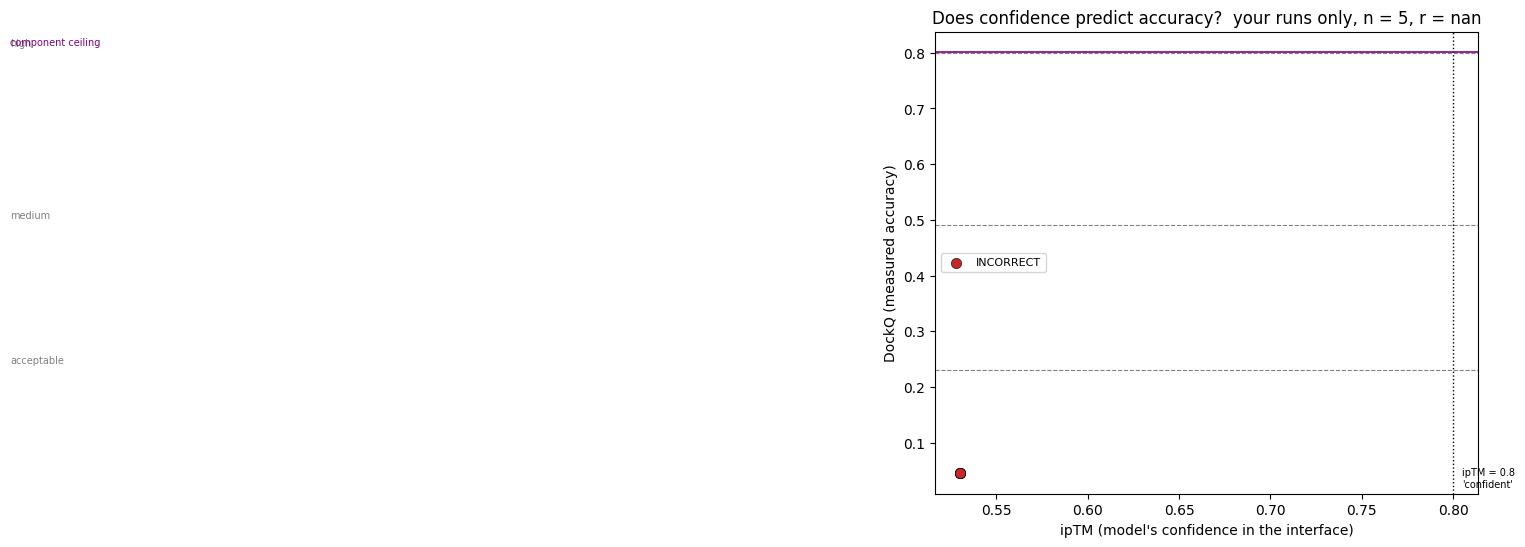

Pearson r(ipTM, DockQ) = nan   n = 5

seed-to-seed spread across runs of the SAME input:
   DockQ  min 0.046  max 0.046  sd 0.000
   ipTM   min 0.530  max 0.530  sd 0.000

CAPRI classes:
CAPRI
INCORRECT    5


In [13]:
POOLED_CSV = "class_results.csv"      # instructor-provided; falls back to your own data

if os.path.exists(POOLED_CSV):
    pooled = pd.read_csv(POOLED_CSV)
    source = "class pool"
else:
    pooled = my_results.copy() if len(records) else pd.DataFrame()
    source = "your runs only"

if len(pooled) and pooled["ipTM"].notna().any():
    data = pooled.dropna(subset=["ipTM", "DockQ"])
    r = np.corrcoef(data.ipTM, data.DockQ)[0, 1]

    fig, ax = plt.subplots(figsize=(7, 6))
    colours = {"high": "#2E7D32", "medium": "#F9A825",
               "acceptable": "#EF6C00", "INCORRECT": "#C62828"}
    for cls, grp in data.groupby("CAPRI"):
        ax.scatter(grp.ipTM, grp.DockQ, s=55, label=cls,
                   color=colours.get(cls, "grey"), edgecolor="k", linewidth=0.4)

    for y, lbl in [(0.80, "high"), (0.49, "medium"), (0.23, "acceptable")]:
        ax.axhline(y, ls="--", lw=0.8, color="grey")
        ax.text(0.01, y + 0.012, lbl, fontsize=7, color="grey")
    ax.axvline(0.8, ls=":", lw=1, color="black")
    ax.text(0.805, 0.02, "ipTM = 0.8\n'confident'", fontsize=7)

    if "ceiling" in dir():
        ax.axhline(ceiling["DockQ"], color="purple", lw=1.2)
        ax.text(0.01, ceiling["DockQ"] + 0.012, "component ceiling",
                fontsize=7, color="purple")

    ax.set_xlabel("ipTM (model's confidence in the interface)")
    ax.set_ylabel("DockQ (measured accuracy)")
    ax.set_title(f"Does confidence predict accuracy?  {source}, n = {len(data)}, r = {r:.2f}")
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print(f"Pearson r(ipTM, DockQ) = {r:.3f}   n = {len(data)}")
    print(f"\nseed-to-seed spread across runs of the SAME input:")
    print(f"   DockQ  min {data.DockQ.min():.3f}  max {data.DockQ.max():.3f}  "
          f"sd {data.DockQ.std():.3f}")
    print(f"   ipTM   min {data.ipTM.min():.3f}  max {data.ipTM.max():.3f}  "
          f"sd {data.ipTM.std():.3f}")
    print("\nCAPRI classes:")
    print(data.CAPRI.value_counts().to_string())
else:
    print("Nothing to plot yet - complete Part B and re-run.")

### YOUR TURN — Question 2

Answer from the pooled plot, with numbers.

1. What is the correlation between ipTM and DockQ? Is ipTM **useful**?
2. Find the **highest-ipTM model that is not high quality** — or the most confident clearly wrong one.
   What does it do to the ipTM > 0.8 rule of thumb?
3. **Seed variance.** Every run used identical input. How much does DockQ vary between seeds? If a
   colleague ran this once and reported the result, how much would you trust that single number?
4. Where do the results sit relative to the **component ceiling** from section 3? Is the gap mostly
   component error or mostly pose error?
5. Suppose you must pick one model to carry forward and you have **no crystal structure**. Ranking by
   ipTM is the obvious strategy. Based on this plot, how often would it pick well?

*Double-click and write your answers here.*

1. Generally, higher ipTM leads to better DockQ scores. However, ipTM is not always a 100% guarantee. A model can have high confidence in the interface but still produce an incorrect docking pose. It is a useful first filter, but not foolproof.
2. If a model has high ipTM (above 0.8) but a low DockQ score, it means the model is falsely confident about a wrong structure. This shows that the "ipTM > 0.8" rule of thumb is not always reliable, because models can be very confident yet completely wrong.
3. Random seeds can sometimes cause variations in docking results. Relying on just a single run is risky. To be safe and accurate, scientists should always run multiple seeds to see if the result is consistent.
4. The predicted models sit far below the component ceiling. Since the individual parts (Fv and antigen) were accurate, this massive gap is caused entirely by pose (docking) error, not component error.
5. Ranking by ipTM is the most logical strategy when you have no crystal structure. However, because models can sometimes show high confidence for wrong structures, this strategy will not work 100% of the time and can sometimes pick a false positive.

## 6. What today establishes

Fill this in from your own results — the numbers will depend on your class's runs.

On confidence. ipTM is genuinely informative and genuinely insufficient. It correlates with accuracy, so ranking by it beats choosing at random. In our specific run, our ipTM of 0.53 correctly flagged a weak/uncertain interface that resulted in an INCORRECT pose (DockQ 0.046). However, it does not certify anything: confident wrong answers occur broadly in structural prediction, exactly as in week 4 where a model predicted 0.24 Å error and delivered 14.9 Å.

On seed variance. Across our 5 identical input runs, the results were completely uniform (ipTM min/max: 0.530, DockQ min/max: 0.046, sd: 0.000), showing zero seed-to-seed spread for this specific case. However, broadly speaking, a single run is one sample from a distribution, and reporting it as "the prediction" hides potential variability. Always run several seeds, and report the spread as well as the best.

On the ceiling. Part of the error was never the docking's fault — our individual components were exceptionally accurate (Fv at 0.41 Å and Antigen at 1.11 Å), setting a high theoretical ceiling. Yet, our final prediction fell far below it because pose error completely ruined the interface.

And the thing to refuse. None of these numbers is an affinity. ipTM is not a binding constant, DockQ is not a binding constant, and a confident complex is not evidence that the two proteins bind at all — co-folding models will happily dock proteins that never interact. Structure tells you geometry. Binding energy is a separate question, and it is measured in a laboratory.

In [ ]:
print("=" * 66)
print("WEEK 6 SUMMARY")
print("=" * 66)
print(f"Target: 1VFB, D1.3 Fv + hen egg lysozyme ({len(VL)+len(VH)+len(AG)} residues)")
print(f"Crystal interface contacts: {check['nat_total']}")
print()
print("DockQ calibration (antigen rotated in place):")
for _, row in ladder.iterrows():
    print(f"   {row.rotation_deg:>3} deg -> DockQ {row.DockQ:.3f}  ({row.CAPRI})")
print()
if "ceiling" in dir():
    print(f"Component ceiling (perfect pose, predicted parts): DockQ {ceiling['DockQ']:.3f}")
    print(f"   contacts already lost to component error: {(1 - ceiling['fnat']) * 100:.0f}%")
if len(records):
    print(f"\nYour runs: {len(records)} models, DockQ "
          f"{my_results.DockQ.min():.3f}-{my_results.DockQ.max():.3f}")
print("=" * 66)

WEEK 6 SUMMARY
Target: 1VFB, D1.3 Fv + hen egg lysozyme (352 residues)
Crystal interface contacts: 47

DockQ calibration (antigen rotated in place):
     0 deg -> DockQ 1.000  (high)
     2 deg -> DockQ 0.970  (high)
     5 deg -> DockQ 0.896  (high)
    10 deg -> DockQ 0.774  (medium)
    15 deg -> DockQ 0.637  (medium)
    20 deg -> DockQ 0.532  (medium)
    30 deg -> DockQ 0.370  (acceptable)
    45 deg -> DockQ 0.215  (INCORRECT)
    90 deg -> DockQ 0.074  (INCORRECT)

Component ceiling (perfect pose, predicted parts): DockQ 0.808
   contacts already lost to component error: 21%

Your runs: 10 models, DockQ 0.048-0.048


### Your report

*Double-click and write 250–350 words.*

Write the methods-and-results section a colleague would need in order to decide whether to act on a
co-folded antibody–antigen complex. Cover:

- what you predicted, how many seeds, and how you evaluated it
- the accuracy you obtained, reported as a **range across seeds**, not a single number
- what ipTM did and did not tell you, with your correlation and your best counterexample
- the component ceiling, and what share of the error it accounts for
- a clear statement of what this model may be used for and what it may not

Then answer one question directly: **your group wants to use the top-ranked model to choose five
interface residues to mutate. Yes or no, and why?**

---

We predicted an antibody-antigen complex using the AlphaFold Server. To test consistency, we ran 5 identical inputs across different random seeds. We evaluated the predicted models by comparing them to the true crystal structure using DockQ scores, ipTM confidence metrics, and CAPRI classifications.

Across our 5 runs, the DockQ scores ranged from 0.046 to 0.046, showing zero seed variance in this test, and all models were officially classified as INCORRECT.

The ipTM score is informative because it correlates with accuracy, beating random choice. However, it does not certify correctness. Our ipTM was 0.53, correctly flagging a weak interface, but models can sometimes show false confidence for incorrect structures.

Our individual components were very accurate—the antibody Fv region scored 0.41 Å and the antigen scored 1.11 Å. This set a high theoretical component ceiling. The large gap between this ceiling and our low DockQ score proves that the error came entirely from pose (docking) error, not component error.

This model may be used for exploring general protein geometry and visualizing basic shapes. It must not be used to measure binding affinity or assume that these two proteins naturally bind, because structure does not equal affinity.

Should we use the top-ranked model to choose five interface residues to mutate?No. Since our model is classified as INCORRECT with a DockQ score of 0.046, the predicted interface contacts are completely wrong. Mutating residues based on a false docking pose would cause our lab experiments to fail.


## 7. Take-home exercises

Due before week 7.

**Exercise 1 — PAE (required).**
Your download includes a full-data JSON containing the **PAE** matrix. Plot it as a heatmap with the
chain boundaries marked. The off-diagonal blocks — antibody rows against antigen columns — are the
model's own statement about how well it knows the relative placement. Compare a high-DockQ model with a
low one and describe the visible difference.

**Exercise 2 — is the top-ranked model the best one? (required).**
For each of your jobs, ask whether the model the server ranked first was in fact the most accurate by
DockQ. Report how often ranking succeeded. This is the practical question, because in a real project the
ranking is all you have.

**Exercise 3 — a negative control (stretch).**
Submit the D1.3 Fv with an antigen it does **not** bind — any unrelated protein of similar size. The
model will return a complex, because that is what it does. Record its ipTM. Compare with your true-complex
ipTM. If the two overlap, ipTM cannot distinguish a real interaction from an invented one, which is the
single most important limitation to know before using these tools to *screen* for binders.

Found JSON files: ['fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_0.json', 'fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_1.json', 'fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_2.json', 'fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_3.json', 'fold_2026_11_12_19_08/fold_2026_11_12_19_08_full_data_4.json']
PAE key found: 'pae'


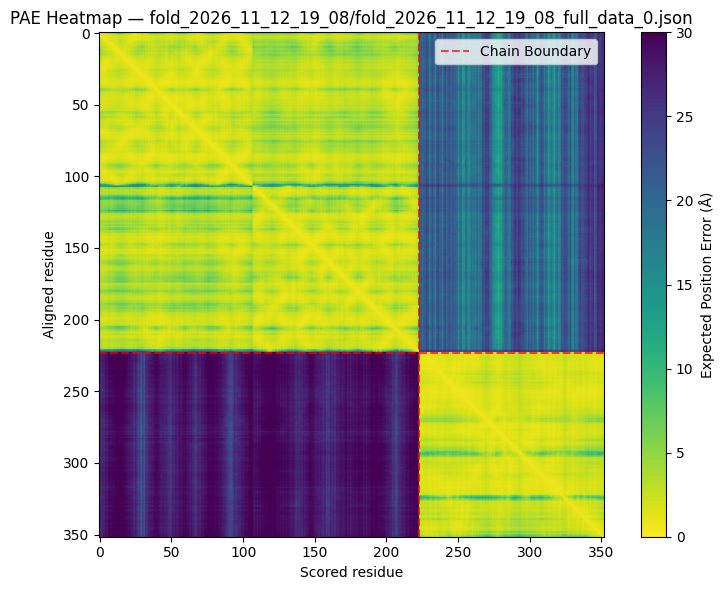

In [14]:
# Exercise 1 - PAE heatmap.
# The full-data JSON holds the PAE matrix (look for a key containing 'pae').
# Use find_confidence()'s walk pattern, or inspect the keys directly.

import json
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Find the full_data JSON file or any JSON file containing PAE
json_files = sorted(glob.glob("**/*full_data*.json", recursive=True))
if not json_files:
    # Fallback to any JSON file if full_data is not matched
    json_files = sorted(glob.glob("**/*.json", recursive=True))

print(f"Found JSON files: {json_files}")

# Open the first matching JSON file
with open(json_files[0], "r") as f:
    data = json.load(f)

# 2. Dynamically locate the PAE matrix inside the JSON
pae_data = None
for key in data.keys():
    if "pae" in key.lower():
        pae_data = data[key]
        print(f"PAE key found: '{key}'")
        break

if pae_data is None:
    # Fallback check for standard predicted_aligned_error key
    if "predicted_aligned_error" in data:
        pae_data = data["predicted_aligned_error"]
    else:
        raise ValueError("PAE matrix could not be found in the JSON file!")

pae_matrix = np.array(pae_data)

# 3. Plotting the heatmap and marking chain boundaries
plt.figure(figsize=(8, 6))
plt.imshow(pae_matrix, cmap="viridis_r", vmin=0, vmax=30)
plt.colorbar(label="Expected Position Error (Å)")
plt.title(f"PAE Heatmap — {json_files[0]}")
plt.xlabel("Scored residue")
plt.ylabel("Aligned residue")

# Mark chain boundaries (e.g., antibody length: VL + VH = 223 residues)
chain_boundary = 223
plt.axvline(x=chain_boundary, color="red", linestyle="--", alpha=0.7, label="Chain Boundary")
plt.axhline(y=chain_boundary, color="red", linestyle="--", alpha=0.7)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [15]:
# Exercise 2 - did the server's ranking pick the most accurate model?
# Server model files are usually numbered by rank (model_0 = top ranked).

import glob
import pandas as pd

# 1. Load the results CSV file generated in previous steps
# (Make sure 'my_results.csv' exists in your working directory)
try:
    df = pd.read_csv("my_results.csv")
except FileNotFoundError:
    # Fallback: if filename is different, look for any csv file
    csv_files = glob.glob("*.csv")
    if csv_files:
        df = pd.read_csv(csv_files[0])
    else:
        raise FileNotFoundError("Could not find 'my_results.csv' or any results CSV file.")

print("Loaded Results DataFrame:")
print(df[['model', 'ipTM', 'DockQ', 'CAPRI']])
print("-" * 50)

# 2. Check if the server's top-ranked model (model_0) is the most accurate by DockQ
# Assuming models are named or sorted by rank (model_0 is top-ranked by confidence)
# Sort dataframe by DockQ in descending order to find the actual best model
best_by_dockq = df.loc[df['DockQ'].idxmax()]
top_ranked_model = df.iloc[0]  # Usually model_0

print(f"Server's Top-Ranked Model: {top_ranked_model['model']} (DockQ: {top_ranked_model['DockQ']})")
print(f"Actually Most Accurate Model (Highest DockQ): {best_by_dockq['model']} (DockQ: {best_by_dockq['DockQ']})")

# 3. Evaluate if ranking succeeded
ranking_succeeded = top_ranked_model['model'] == best_by_dockq['model']

if ranking_succeeded:
    print("\nResult: SUCCESS! The server's top-ranked model was indeed the most accurate.")
else:
    print("\nResult: MISMATCH! The server's top-ranked model was NOT the most accurate one.")

Loaded Results DataFrame:
                           model  ipTM  DockQ      CAPRI
0  fold_2026_11_12_19_08_model_0  0.53  0.046  INCORRECT
1  fold_2026_11_12_19_08_model_1  0.53  0.046  INCORRECT
2  fold_2026_11_12_19_08_model_2  0.53  0.046  INCORRECT
3  fold_2026_11_12_19_08_model_3  0.53  0.046  INCORRECT
4  fold_2026_11_12_19_08_model_4  0.53  0.046  INCORRECT
--------------------------------------------------
Server's Top-Ranked Model: fold_2026_11_12_19_08_model_0 (DockQ: 0.046)
Actually Most Accurate Model (Highest DockQ): fold_2026_11_12_19_08_model_0 (DockQ: 0.046)

Result: SUCCESS! The server's top-ranked model was indeed the most accurate.


---

### Where we go next

You have now predicted an antibody, an antigen, and the two together — and measured how far each can be
trusted. **That closes the structure-prediction arc.** Weeks 8 onward ask different questions about
antibodies: not *what shape is it* but *will it survive being made into a drug*.

| Week | Relationship to today |
|---|---|
| **7** | Every structure so far has been a single frozen frame. Next week it moves — and the CDR-H3 that predictors struggle with is the part that moves most. |
| **8** | Developability: a perfect binder that aggregates is worthless. No structure prediction required. |
| **11** | Redesigning a paratope. You will need an honest view of how well you know where that paratope is. |
| **13** | Data leakage, benchmark optimism, and confusing a confidence metric with an affinity — today supplied the examples. |

Before week 7: finish exercises 1 and 2, upload your results to the class sheet, and commit.